# 02 — Analisis Visual: Keadaan Mata dan Sleepiness

> **Dua eksperimen terpisah:** MRL / eye state dan DROZY / KSS sleepiness  
> **Unit evaluasi:** gambar pada subjek holdout; original test pada subjek LOSO  
> **Mode default:** DEMO — hasil tersimpan, dengan preprocessing, EAR, dan inference langsung

[README proyek](../../README.md) · [MRL](https://mrl.cs.vsb.cz/eyedataset.html) · [DROZY](https://www.drozy.uliege.be/) · [Metodologi dan batasan](../../reports/limitations.md) · [Run All](README.md)

## Ringkasan untuk Pembaca

Gambar mata menjawab apakah mata terbuka atau tertutup; urutan landmark menjawab bagaimana pola mata berubah sepanjang waktu. Notebook ini menjalankan dua penelitian kecil untuk menguji kedua kemampuan tersebut pada orang yang tidak masuk training. Eye state dan KSS sleepiness tidak disatukan menjadi satu label fatigue.

Fatigue berarti kelelahan terkait tuntutan berkelanjutan; sleepiness adalah kecenderungan tertidur. Workload (tuntutan mental), stress (respons tekanan), emotion (emosi), dan eye state (keadaan mata) juga berbeda. Tidak ada skor deteksi fatigue ATC pada notebook ini.

In [1]:
from pathlib import Path
import os
RUN_MODE = os.environ.get('ATC_NOTEBOOK_MODE', 'DEMO').upper()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/notebook_v3.yaml').exists())
os.chdir(ROOT)
import yaml
config = yaml.safe_load(Path('configs/notebook_v3.yaml').read_text())
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[key] = str(config['threads'])
os.environ['OPENCV_FFMPEG_THREADS'] = str(config['opencv_threads'])
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from atc_fatigue.research.runs import Run, cached_run, project_config, mode_from_environment, metrics_base, save_model
from atc_fatigue.research.data import local_manifest, frozen_split, prediction_table, public_errors, verify_cached_predictions
from atc_fatigue.research.plots import (COLORS, EMOTIONS, FigureBook, theme, run_card, flow,
                                      histogram, model_bars, confusion_pair, split_chart, recall_chart)
config = project_config()
RUN_MODE = mode_from_environment(config['mode_default'])
thread_limit = threadpool_limits(limits=config['threads'])
theme()
warning_context = warnings.catch_warnings(record=True)
warning_records = warning_context.__enter__()
print(f'Mode {RUN_MODE} | CPU maksimal {config["threads"]} thread | offline | kernel proyek')

Mode DEMO | CPU maksimal 4 thread | offline | kernel proyek


/home/nafisnaufal1426/competition/orie/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. BAGIAN A — MRL: Mata Terbuka atau Tertutup

**Pertanyaan:** dapatkah model mengenali keadaan mata pada orang yang belum pernah dilihat saat training?

MRL menyediakan gambar mata IR dan label filename: **0 = tertutup**, **1 = terbuka**. Gambar tidak memiliki urutan waktu untuk menghitung kedipan. Subset yang dipakai dibatasi per subjek/kelas; proporsinya bukan prevalensi penutupan mata dalam operasi nyata.

Sumber MRL menyatakan penggunaan publik, tetapi izin redistribusi foto belum terverifikasi. Kita memproses gambar asli secara lokal dan menggunakan ilustrasi sintetis untuk demonstrasi gambar/HOG. Tidak ada foto mata peserta yang di-embed ke notebook.

In [2]:
mrl_manifest = local_manifest(config['visual']['mrl_manifest'], target='eye_state')
mrl_rights = {'source': 'https://mrl.cs.vsb.cz/eyedataset.html', 'variant': 'official 2018_01; existing bounded subset',
              'rights': 'local research; redistribution permission not established', 'public_preview': 'synthetic eye patch only'}
mrl_limits = ['eye state is not fatigue; bounded per-subject/class subset',
              'fixed original subject split; no hyperparameter tuning', 'near-duplicates not exhaustively audited']
if RUN_MODE == 'FULL':
    mrl_run = Run.create('mrl_eye_state', '02_visual_analysis.ipynb', config, mrl_manifest,
                         'mrl-hog-32x64-v1', mrl_rights, mrl_limits)
else:
    mrl_run, mrl_metrics = cached_run('mrl_eye_state', config)
mrl_book = FigureBook(mrl_run, RUN_MODE, config)
run_card(mrl_run, RUN_MODE, 'FULL: dihitung pada bagian evaluasi' if RUN_MODE == 'FULL' else
         f"Eye state Macro F1 {mrl_metrics['models']['hog_linear_svm']['test']['macro_f1']:.4f}")
display(pd.DataFrame([{'Gambar': len(mrl_manifest), 'Subjek': mrl_manifest.subject_id.nunique(),
                       'Label': '0 tertutup / 1 terbuka', 'Duplikasi byte': mrl_manifest.source_checksum.duplicated().sum()}]))

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; contoh ekstraksi/inference diproses langsung** |
| Run ID sumber | `20261022T082130453246Z_seed42_6453bd` |
| Status eksperimen sumber | completed |
| Dataset / target | mrl_eye / eye_state |
| Sampel / subjek | 5285 / 37 |
| Unit evaluasi | image; held-out subject |
| Hasil utama | Eye state Macro F1 0.7877 |

,Gambar,Subjek,Label,Duplikasi byte
0,5285,37,0 tertutup / 1 terbuka,0


### 1.1 Dari gambar ke HOG

**Grayscale** merangkum intensitas terang-gelap. Gambar diubah ke ukuran **32 × 64 piksel**. **HOG** (*Histogram of Oriented Gradients*) menghitung pola arah tepi, sehingga model menerima angka tentang bentuk, bukan nama orang. Bentuk tabel dan preprocessing contoh asli ditunjukkan sebelum training.

In [3]:
from atc_fatigue.io.mrl import image_features
from skimage.io import imread
from skimage.transform import resize
from skimage.feature import hog
live_mrl_hog = image_features(mrl_manifest.iloc[:1], config['visual']['mrl_image_size'])
real_eye = imread(mrl_manifest.original_path.iloc[0], as_gray=True)
resized_eye = resize(real_eye, tuple(config['visual']['mrl_image_size']), anti_aliasing=True)
display(pd.DataFrame([{'Tahap': 'Gambar asli', 'Bentuk': str(real_eye.shape), 'Representasi': 'Intensitas grayscale'},
                      {'Tahap': 'Resize', 'Bentuk': str(resized_eye.shape), 'Representasi': '32 × 64 piksel'},
                      {'Tahap': 'HOG — FRESH', 'Bentuk': str(live_mrl_hog.filter(regex='^hog_').shape), 'Representasi': '756 fitur tepi'}]))
display(live_mrl_hog.filter(regex='^hog_').iloc[:, :6].rename(index={0: 'Contoh asli'}))

,Tahap,Bentuk,Representasi
0,Gambar asli,"(102, 102)",Intensitas grayscale
1,Resize,"(32, 64)",32 × 64 piksel
2,HOG — FRESH,"(1, 756)",756 fitur tepi


,hog_0000,hog_0001,hog_0002,hog_0003,hog_0004,hog_0005
Contoh asli,0.050011,0.035776,0.288072,0.201027,0.259804,0.077059


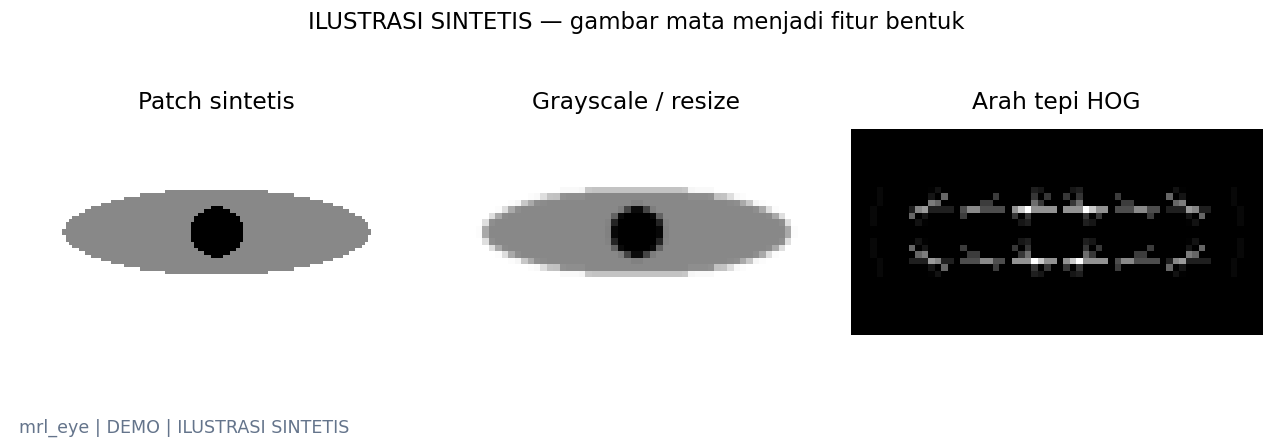

**Yang terlihat:** Bentuk mata buatan berubah menjadi peta arah tepi.

**Artinya:** HOG merangkum bentuk lokal menjadi vektor numerik berukuran tetap.

**Perlu diingat:** Ilustrasi tidak dipakai untuk training; 756 fitur contoh di tabel berasal dari gambar asli.

*Sumber: `20261022T082130453246Z_seed42_6453bd` · CACHED + contoh diproses langsung.*

In [4]:
yy, xx = np.mgrid[-1:1:64j, -2:2:128j]
synthetic_eye = np.full(xx.shape, 0.85)
synthetic_eye[(xx/1.5)**2 + (yy/0.42)**2 < 1] = 0.5
synthetic_eye[xx**2 + yy**2 < 0.25**2] = 0.1
synthetic_resized = resize(synthetic_eye, (32, 64), anti_aliasing=True)
_, synthetic_hog_image = hog(synthetic_resized, orientations=9, pixels_per_cell=(8, 8),
                             cells_per_block=(2, 2), visualize=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, image, label in zip(axes, [synthetic_eye, synthetic_resized, synthetic_hog_image],
                            ['Patch sintetis', 'Grayscale / resize', 'Arah tepi HOG']):
    ax.imshow(image, cmap='gray'); ax.set_title(label); ax.set_axis_off()
fig.suptitle('ILUSTRASI SINTETIS — gambar mata menjadi fitur bentuk')
mrl_book.show(fig, 'gambar_ke_hog_sintetis', 'Bentuk mata buatan berubah menjadi peta arah tepi.',
              'HOG merangkum bentuk lokal menjadi vektor numerik berukuran tetap.',
              'Ilustrasi tidak dipakai untuk training; 756 fitur contoh di tabel berasal dari gambar asli.', synthetic=True)

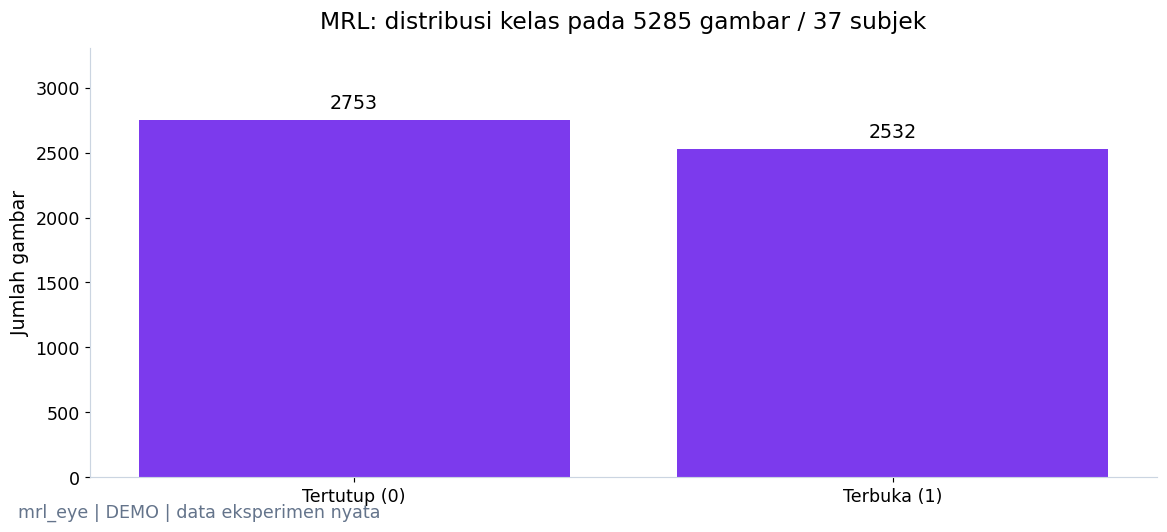

**Yang terlihat:** Tertutup 2753 gambar; terbuka 2532 gambar.

**Artinya:** Kedua kelas tersedia untuk membandingkan model dengan tebakan kelas mayoritas.

**Perlu diingat:** Sampling dibatasi per subjek/kelas; ini bukan frekuensi keadaan mata di tempat kerja.

*Sumber: `20261022T082130453246Z_seed42_6453bd` · CACHED + contoh diproses langsung.*

In [5]:
counts = mrl_manifest.target_value.value_counts().sort_index()
fig, ax = plt.subplots(layout='constrained')
bars = ax.bar(['Tertutup (0)', 'Terbuka (1)'], counts.values, color=COLORS['visual'])
ax.bar_label(bars, padding=5)
ax.set(ylabel='Jumlah gambar', ylim=(0, counts.max()*1.2),
       title=f'MRL: distribusi kelas pada {len(mrl_manifest)} gambar / {mrl_manifest.subject_id.nunique()} subjek')
mrl_book.show(fig, 'distribusi_kelas_mrl', f'Tertutup {counts.loc[0]} gambar; terbuka {counts.loc[1]} gambar.',
              'Kedua kelas tersedia untuk membandingkan model dengan tebakan kelas mayoritas.',
              'Sampling dibatasi per subjek/kelas; ini bukan frekuensi keadaan mata di tempat kerja.')

### 1.2 Ekstraksi subset dan split yang dibekukan

**Subject-disjoint split** berarti satu orang hanya masuk satu bagian data. Test menjawab generalisasi ke orang baru pada subset ini. Keanggotaan train/validation/test memakai manifest eksperimen lama yang sudah dibekukan; kita tidak memilih split setelah melihat skor.

Checksum byte dan decoded pixels diperiksa sebelum model dilatih. Kesamaan piksel yang melintasi split ditolak. Ini belum merupakan audit seluruh near-duplicate yang mungkin terjadi pada gambar serupa.

In [6]:
if RUN_MODE == 'FULL':
    mrl_hog = image_features(mrl_manifest, config['visual']['mrl_image_size'])
    mrl_data = mrl_manifest.merge(mrl_hog, on='sample_id', validate='one_to_one')
    decoded_duplicates = int(mrl_data.pixel_checksum.duplicated().sum())
    mrl_data = mrl_data.drop_duplicates('pixel_checksum').reset_index(drop=True)
    mrl_data = frozen_split(mrl_data, config['frozen_splits']['mrl_eye_state'])
else:
    mrl_data = pd.read_parquet(mrl_run.path / 'features/features.parquet')
    decoded_duplicates = json.loads((mrl_run.path / 'data_qc.json').read_text())['decoded_duplicates_removed']
    assert set(mrl_data.sample_id) == set(mrl_manifest.sample_id)
mrl_columns = [c for c in mrl_data if c.startswith('hog_')]
assert len(mrl_columns) == 756 and mrl_data.groupby('subject_id').split.nunique().max() == 1
np.testing.assert_allclose(mrl_data.loc[mrl_data.sample_id.eq(mrl_manifest.sample_id.iloc[0]), mrl_columns].iloc[0],
                           live_mrl_hog[mrl_columns].iloc[0])
mrl_sizes = mrl_data.groupby('split').size().to_dict()
display(mrl_data.groupby('split').agg(Gambar=('sample_id','size'), Subjek=('subject_id','nunique')))
display(pd.DataFrame([{'Duplikasi decoded dihapus': decoded_duplicates, 'Overlap subjek antarbagian': 0}]))
if RUN_MODE == 'FULL':
    mrl_run.features(mrl_data, mrl_columns, 'mrl-hog-32x64-v1')
    mrl_data[['sample_id','subject_id','target_value','source_checksum','pixel_checksum','split']].to_csv(mrl_run.file('split_manifest.csv'), index=False)

,Gambar,Subjek
split,,
test,1159,8
train,3234,23
validation,892,6


,Duplikasi decoded dihapus,Overlap subjek antarbagian
0,0,0


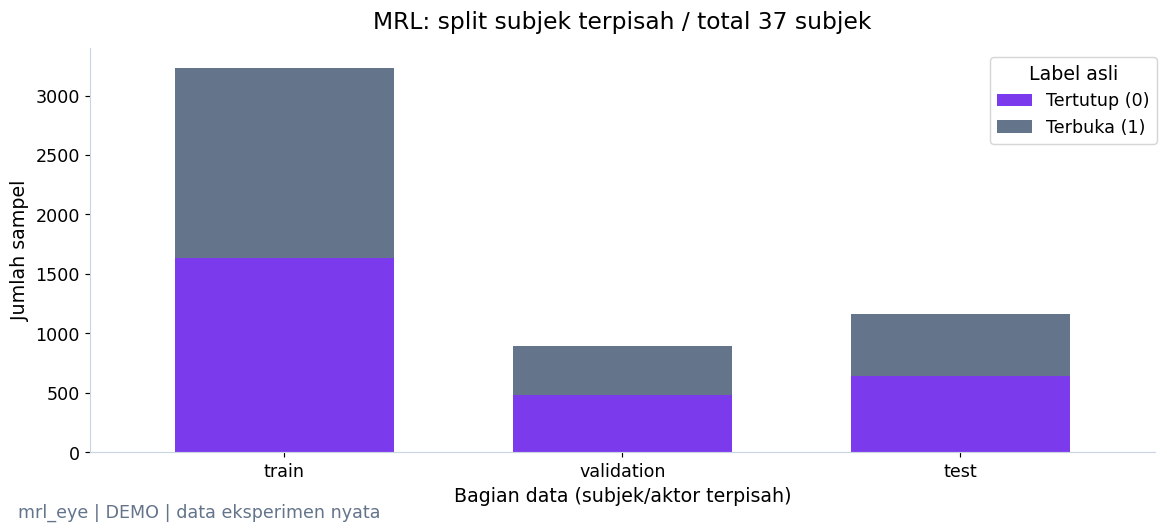

**Yang terlihat:** Train 3234, validation 892, test 1159 gambar; overlap subjek nol.

**Artinya:** Skor test menilai subjek yang tidak digunakan untuk fit preprocessing atau classifier.

**Perlu diingat:** Gambar dalam orang yang sama tetap berkorelasi; ini bukan ribuan peserta independen.

*Sumber: `20261022T082130453246Z_seed42_6453bd` · CACHED + contoh diproses langsung.*

In [7]:
fig = split_chart(mrl_data, f'MRL: split subjek terpisah / total {mrl_data.subject_id.nunique()} subjek')
mrl_book.show(fig, 'split_mrl',
              f"Train {mrl_sizes['train']}, validation {mrl_sizes['validation']}, test {mrl_sizes['test']} gambar; overlap subjek nol.",
              'Skor test menilai subjek yang tidak digunakan untuk fit preprocessing atau classifier.',
              'Gambar dalam orang yang sama tetap berkorelasi; ini bukan ribuan peserta independen.')

### 1.3 Training baseline yang benar-benar dipanggil

**Dummy mayoritas** selalu menebak kelas paling banyak pada training. **Linear SVM** mencari batas linear pada fitur HOG. **Imputer** mengisi fitur hilang dengan median training; **scaler** menyetarakan skala berdasarkan training saja. Pipeline memastikan preprocessing tidak mempelajari test.

Konfigurasi tetap: SVM `C=1`, class weight balanced, seed 42. Tidak ada pencarian hyperparameter. Pada FULL, `fit` di bawah menjalankan training; pada DEMO, checkpoint asli dimuat dan prediksi test diverifikasi terhadap hasil tersimpan.

Pada evaluasi, **precision** adalah proporsi prediksi suatu kelas yang benar; **recall** adalah proporsi anggota kelas asli yang berhasil dikenali. **Support** menyebut jumlah sampel kelas tersebut, bukan jumlah subjek.

In [8]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import Ridge
from atc_fatigue.models.baselines import classification_metrics
mrl_training, mrl_holdout = mrl_data[mrl_data.split.eq('train')], mrl_data[~mrl_data.split.eq('train')]
if RUN_MODE == 'FULL':
    mrl_models = {
        'dummy_majority': DummyClassifier(strategy='most_frequent'),
        'hog_linear_svm': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
            LinearSVC(C=config['visual']['svm_c'], class_weight='balanced', dual='auto', random_state=config['seed'], max_iter=20000)),
    }
    mrl_scores, mrl_prediction_parts = {}, []
    for model_name, model in mrl_models.items():
        model.fit(mrl_training[mrl_columns], mrl_training.target_value)
        save_model(mrl_run, model_name, model, mrl_columns, mrl_holdout)
        mrl_scores[model_name] = {'reload_verified': True}
        for partition in ['validation','test']:
            part = mrl_data[mrl_data.split.eq(partition)]
            predicted = model.predict(part[mrl_columns])
            mrl_scores[model_name][partition] = classification_metrics(part.target_value, predicted, [0,1])
            mrl_prediction_parts.append(prediction_table(part, predicted, model_name))
    mrl_predictions = pd.concat(mrl_prediction_parts, ignore_index=True)
    mrl_predictions.to_csv(mrl_run.file('predictions/holdout_predictions.csv'), index=False)
    mrl_metrics = metrics_base(mrl_run, mrl_scores, mrl_sizes, {'0':'closed','1':'open'}, 'dummy_majority')
else:
    mrl_predictions = pd.read_csv(mrl_run.path / 'predictions/holdout_predictions.csv', dtype={'subject_id':str})
    for model_name in mrl_metrics['models']:
        verify_cached_predictions(mrl_run, mrl_data[mrl_data.split.eq('test')], mrl_predictions, model_name)

,macro_f1,balanced_accuracy,accuracy
dummy_majority,0.355753,0.5,0.5522
hog_linear_svm,0.787665,0.787206,0.790336


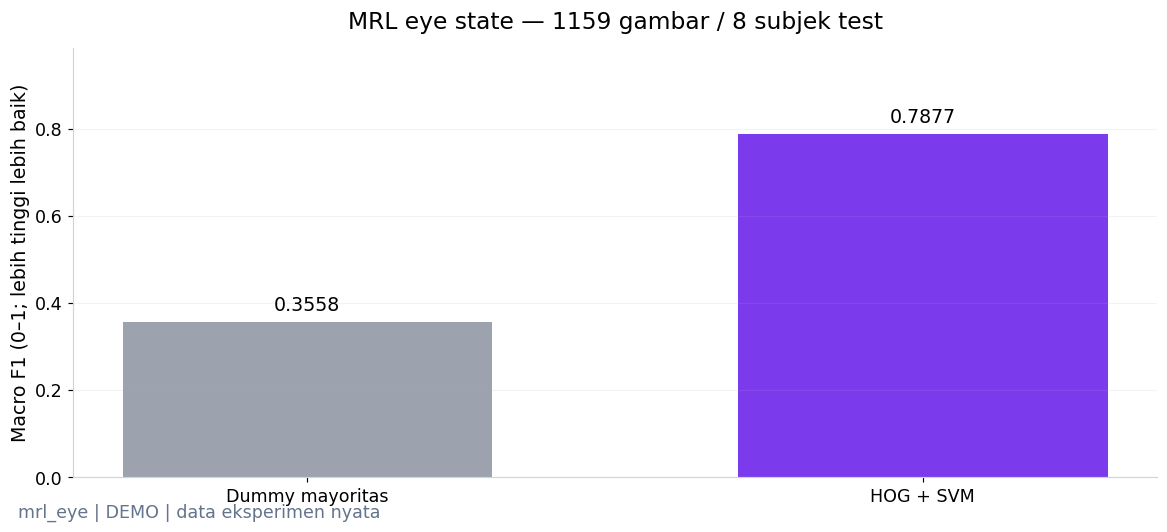

**Yang terlihat:** Macro F1 SVM 0.7877; Dummy 0.3558.

**Artinya:** Macro F1 merata-ratakan F1 tiap kelas, sehingga kedua keadaan mata ikut dinilai.

**Perlu diingat:** Peningkatan di subset ini tidak berarti model mampu mendeteksi fatigue.

*Sumber: `20261022T082130453246Z_seed42_6453bd` · CACHED + contoh diproses langsung.*

In [9]:
mrl_test_scores = {name: value['test'] for name, value in mrl_metrics['models'].items()}
display(pd.DataFrame(mrl_test_scores).T[['macro_f1','balanced_accuracy','accuracy']])
fig = model_bars(mrl_test_scores, 'macro_f1', f'MRL eye state — {mrl_sizes["test"]} gambar / 8 subjek test',
                 'Macro F1 (0–1; lebih tinggi lebih baik)', COLORS['visual'])
mrl_book.show(fig, 'perbandingan_model_mrl',
              f"Macro F1 SVM {mrl_test_scores['hog_linear_svm']['macro_f1']:.4f}; Dummy {mrl_test_scores['dummy_majority']['macro_f1']:.4f}.",
              'Macro F1 merata-ratakan F1 tiap kelas, sehingga kedua keadaan mata ikut dinilai.',
              'Peningkatan di subset ini tidak berarti model mampu mendeteksi fatigue.')

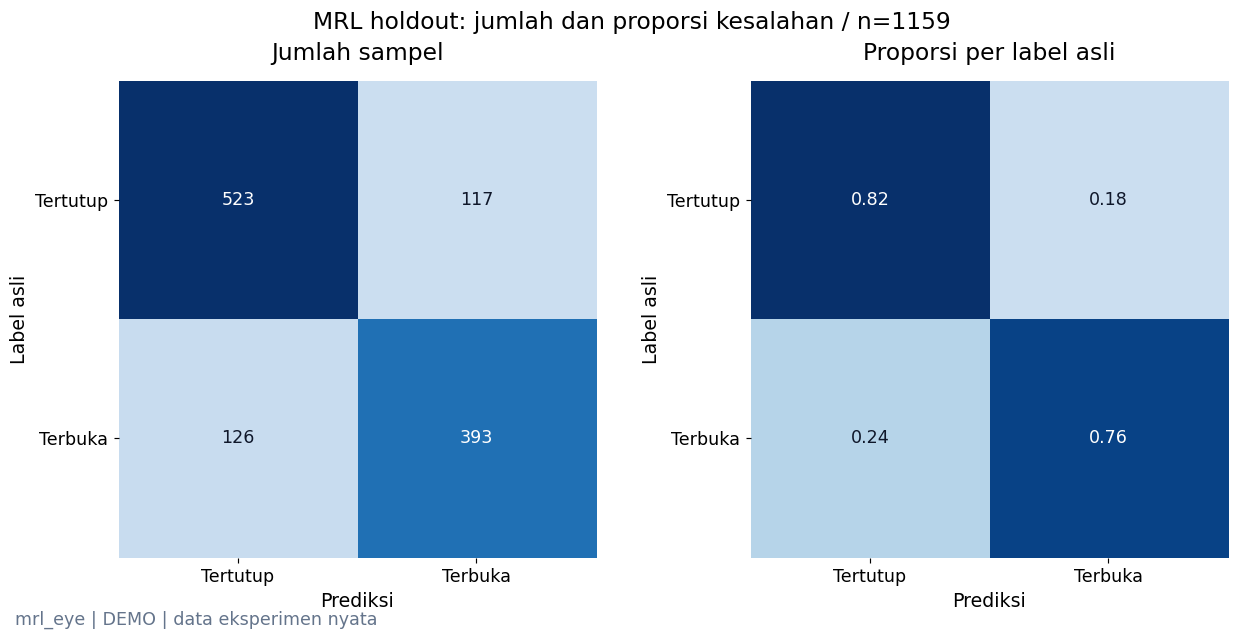

**Yang terlihat:** Dari matriks test, 916 gambar diprediksi benar; sisanya tertukar kelas.

**Artinya:** Baris menyatakan label asli, kolom prediksi; sel di luar diagonal adalah kesalahan.

**Perlu diingat:** Normalisasi dilakukan per baris agar proporsi kesalahan tiap kelas mudah dibandingkan.

*Sumber: `20261022T082130453246Z_seed42_6453bd` · CACHED + contoh diproses langsung.*

In [10]:
mrl_result = mrl_test_scores['hog_linear_svm']
fig = confusion_pair(mrl_result, ['Tertutup','Terbuka'], f'MRL holdout: jumlah dan proporsi kesalahan / n={mrl_sizes["test"]}')
mrl_book.show(fig, 'confusion_mrl',
              f"Dari matriks test, {np.trace(mrl_result['confusion_matrix'])} gambar diprediksi benar; sisanya tertukar kelas.",
              'Baris menyatakan label asli, kolom prediksi; sel di luar diagonal adalah kesalahan.',
              'Normalisasi dilakukan per baris agar proporsi kesalahan tiap kelas mudah dibandingkan.')

,Precision,Recall,F1,Jumlah gambar test
Tertutup,0.805855,0.817187,0.811482,640.0
Terbuka,0.770588,0.757225,0.763848,519.0


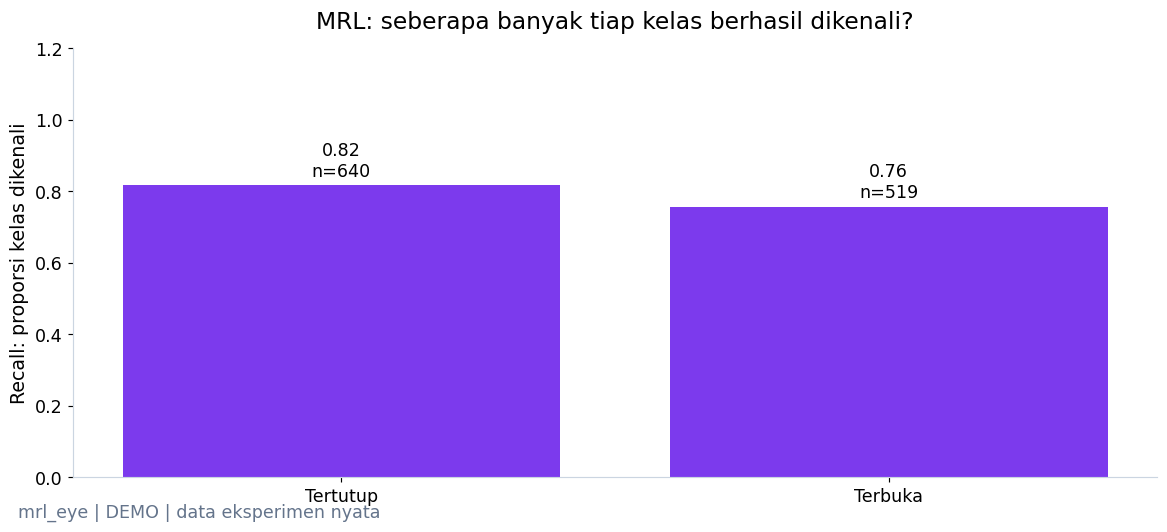

**Yang terlihat:** Recall tertutup 0.817; terbuka 0.757.

**Artinya:** Recall adalah bagian sampel kelas asli yang dikenali dengan benar.

**Perlu diingat:** Kesalahan open/closed belum dapat diterjemahkan menjadi false alarm fatigue.

*Sumber: `20261022T082130453246Z_seed42_6453bd` · CACHED + contoh diproses langsung.*

,Contoh,Label asli,Prediksi
2950,contoh-3b1a6522,0,1
2952,contoh-f789fe7f,0,1
2953,contoh-14817f62,0,1
2955,contoh-9cc089c8,0,1
2956,contoh-861c0936,0,1
2971,contoh-5bd728e0,0,1


In [11]:
mrl_class_report = pd.DataFrame({label:mrl_result['classification_report'][str(code)]
                                     for code,label in [(0,'Tertutup'),(1,'Terbuka')]}).T
mrl_class_report = mrl_class_report.rename(columns={'precision':'Precision','recall':'Recall','f1-score':'F1','support':'Jumlah gambar test'})
display(mrl_class_report)
fig = recall_chart(mrl_result, ['Tertutup','Terbuka'], 'MRL: seberapa banyak tiap kelas berhasil dikenali?', COLORS['visual'])
mrl_book.show(fig, 'recall_mrl',
              f"Recall tertutup {mrl_result['classification_report']['0']['recall']:.3f}; terbuka {mrl_result['classification_report']['1']['recall']:.3f}.",
              'Recall adalah bagian sampel kelas asli yang dikenali dengan benar.',
              'Kesalahan open/closed belum dapat diterjemahkan menjadi false alarm fatigue.')
display(public_errors(mrl_predictions, 'hog_linear_svm'))

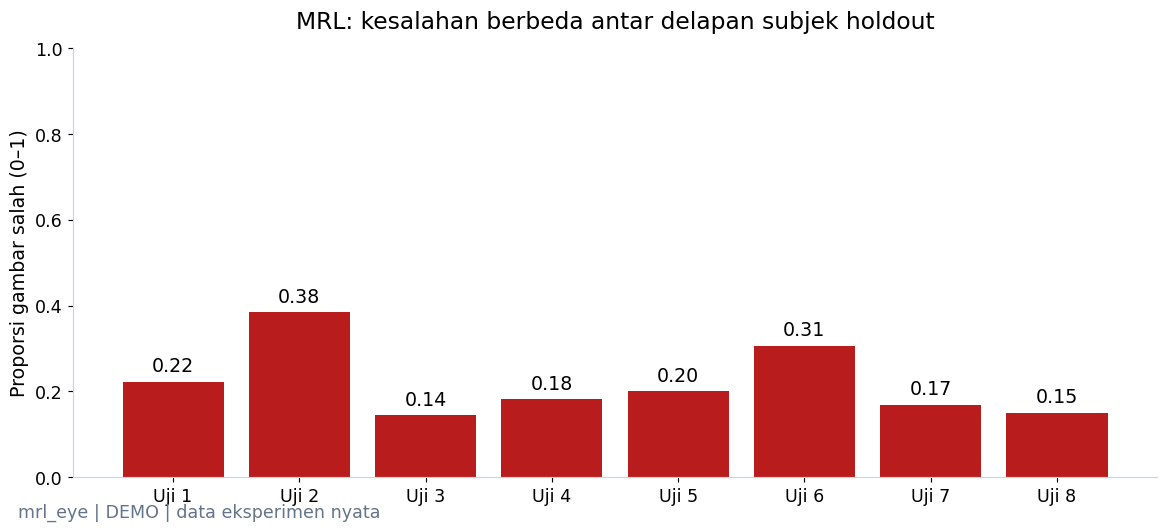

**Yang terlihat:** Proporsi kesalahan per subjek berkisar 0.14–0.38.

**Artinya:** Rata-rata global dapat menyembunyikan perbedaan antarorang.

**Perlu diingat:** ID tampilan disamarkan; tidak ada contoh foto peserta yang dipublikasikan.

*Sumber: `20261022T082130453246Z_seed42_6453bd` · CACHED + contoh diproses langsung.*

In [12]:
mrl_errors = mrl_predictions[mrl_predictions.model.eq('hog_linear_svm') & mrl_predictions.split.eq('test')].copy()
mrl_errors['Salah'] = mrl_errors.truth.ne(mrl_errors.prediction)
subject_error = mrl_errors.groupby('subject_id').Salah.mean().sort_index()
fig, ax = plt.subplots(layout='constrained')
bars = ax.bar([f'Uji {i+1}' for i in range(len(subject_error))], subject_error, color=COLORS['error'])
ax.bar_label(bars, fmt='%.2f', padding=4)
ax.set(ylabel='Proporsi gambar salah (0–1)', ylim=(0,1), title='MRL: kesalahan berbeda antar delapan subjek holdout')
mrl_book.show(fig, 'error_per_subjek_mrl',
              f'Proporsi kesalahan per subjek berkisar {subject_error.min():.2f}–{subject_error.max():.2f}.',
              'Rata-rata global dapat menyembunyikan perbedaan antarorang.',
              'ID tampilan disamarkan; tidak ada contoh foto peserta yang dipublikasikan.')
mrl_book.finish()
if RUN_MODE == 'FULL':
    mrl_run.complete(mrl_metrics, {'evaluation_rows':len(mrl_data), 'decoded_duplicates_removed':decoded_duplicates,
                                 'subject_overlap':0, 'feature_missing_fraction':float(mrl_data[mrl_columns].isna().mean().mean())}, warning_records)

---

## 2. BAGIAN B — DROZY: Pola Mata Sepanjang Waktu dan KSS

**Ini tugas baru dengan label berbeda. Tidak ada satu skor gabungan dengan MRL.**

Pertanyaan pertama: bagaimana koordinat mata menjadi fitur kedipan dan penutupan mata? Pertanyaan kedua: apakah agregat fitur dapat memperkirakan **KSS** (*Karolinska Sleepiness Scale*), penilaian subjektif rasa kantuk skala 1–9, pada orang yang tidak ada dalam training?

DROZY menggunakan satu KSS asli per test. Banyak window dari satu test bukan banyak penilaian manusia independen. Test berulang pada orang yang sama tetap berkorelasi. Data dan wajah dibatasi untuk riset; notebook hanya menampilkan diagram sintetis dan grafik turunan numerik yang terbatas, tanpa gambar wajah.

In [13]:
from atc_fatigue.io.drozy import read_landmarks, process_test
from atc_fatigue.vision.eye_features import ear, ear_68, closure_events, window_features
from atc_fatigue.research.data import kss_test_table, regression_metrics
from sklearn.model_selection import LeaveOneGroupOut
drozy_root = Path(config['visual']['drozy_root'])
if not (drozy_root / 'KSS.txt').exists():
    raise FileNotFoundError('DROZY lokal belum siap; lihat README v3. Tidak ada unduhan otomatis.')
original_kss = np.loadtxt(drozy_root / 'KSS.txt', ndmin=2)
drozy_tests = []
for landmark_path in sorted((drozy_root / 'annotations-auto').glob('*-s2.txt')):
    session = landmark_path.stem.removesuffix('-s2')
    subject, trial = map(int, session.split('-'))
    label = float(original_kss[subject-1, trial-1])
    if 1 <= label <= 9:
        drozy_tests.append({'dataset_id':'drozy','sample_id':f'drozy_test_{session}','subject_id':str(subject),
                            'session_id':session,'target_name':'KSS','target_value':label,
                            'label_source':'original_KSS.txt_subject_test','is_synthetic_pair':False})
drozy_manifest = pd.DataFrame(drozy_tests)

In [14]:
drozy_rights = {'source':'https://www.drozy.uliege.be/', 'variant':'original 2D 68 landmarks + native timestamps + KSS.txt',
                'rights':'research/evaluation only; no redistribution; restricted participant display',
                'public_preview':'synthetic eye geometry and limited derived numeric charts; no faces'}
drozy_limits = ['KSS is sleepiness, not fatigue; repeated tests within 14 subjects',
                'whole-test offline aggregates; no real-time warning',
                'EAR .21 and closure >=500ms uncalibrated; not validated standard PERCLOS']
if RUN_MODE == 'FULL':
    drozy_run = Run.create('drozy_kss','02_visual_analysis.ipynb',config,drozy_manifest,
                           'ear68-duration-v1; test-aggregate-v1',drozy_rights,drozy_limits)
else:
    drozy_run, kss_metrics = cached_run('drozy_kss',config)
drozy_book = FigureBook(drozy_run,RUN_MODE,config)
run_card(drozy_run,RUN_MODE,'FULL: hasil dihitung di evaluasi' if RUN_MODE=='FULL' else
         f"KSS LOSO MAE {kss_metrics['models']['ridge_alpha1']['mae']:.4f} poin")

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; contoh ekstraksi/inference diproses langsung** |
| Run ID sumber | `20261022T082144167968Z_seed42_60423d` |
| Status eksperimen sumber | completed |
| Dataset / target | drozy / KSS |
| Sampel / subjek | 36 / 14 |
| Unit evaluasi | original_test; held-out subject |
| Hasil utama | KSS LOSO MAE 1.4544 poin |

### 2.1 Menghitung EAR dari enam titik

**EAR** (*Eye Aspect Ratio*) membandingkan dua jarak vertikal dengan lebar mata:

`EAR = (jarak p2–p6 + jarak p3–p5) / (2 × jarak p1–p4)`.

EAR tidak memiliki satuan; mata lebih sempit biasanya menghasilkan rasio lebih rendah. Contoh berikut memakai koordinat buatan dan memperlihatkan hitungan langsung. Mapping 68 landmark DROZY memakai indeks 36:42 dan 42:48, yang sudah diperiksa dengan overlay QC lokal pada pekerjaan sebelumnya.

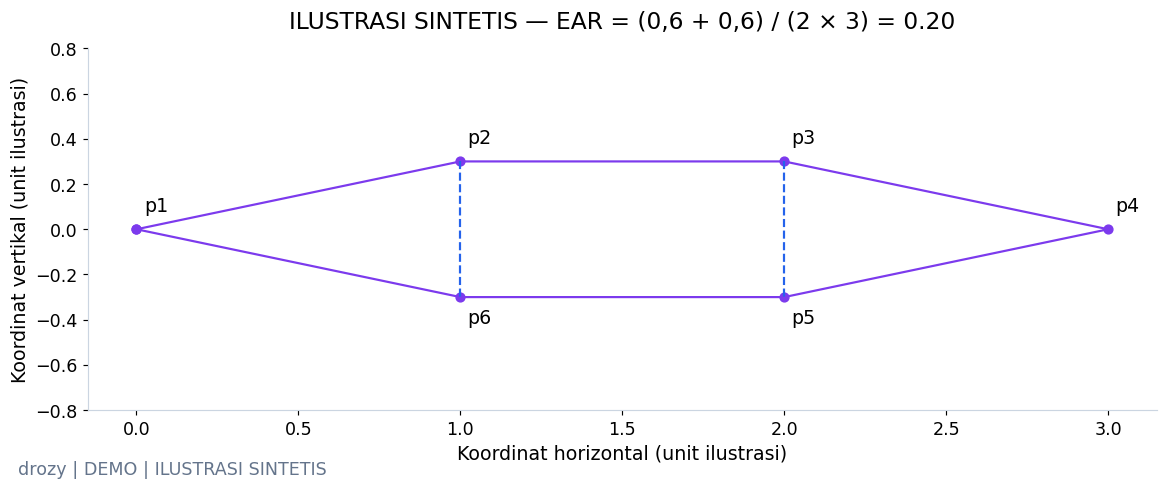

**Yang terlihat:** Enam titik buatan menghasilkan EAR 0,20.

**Artinya:** Rasio mengurangi ketergantungan pada ukuran absolut mata dalam piksel.

**Perlu diingat:** Anatomi, pose, dan landmark error tetap berpengaruh; ini bukan threshold fatigue.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [15]:
illustrated_eye = np.array([[0,0],[1,0.3],[2,0.3],[3,0],[2,-0.3],[1,-0.3]])
illustrated_ear = ear(illustrated_eye)
fig, ax = plt.subplots(figsize=(11,4.4),layout='constrained')
outline = np.vstack([illustrated_eye,illustrated_eye[0]])
ax.plot(outline[:,0],outline[:,1],'-o',color=COLORS['visual'])
for i,(x,y) in enumerate(illustrated_eye):
    ax.annotate(f'p{i+1}',(x,y),xytext=(5,12 if y>=0 else -18),textcoords='offset points')
for a,b in [(1,5),(2,4)]:
    ax.plot(illustrated_eye[[a,b],0],illustrated_eye[[a,b],1],'--',color=COLORS['audio'])
ax.set(xlabel='Koordinat horizontal (unit ilustrasi)',ylabel='Koordinat vertikal (unit ilustrasi)',
       ylim=(-0.8,0.8),title=f'ILUSTRASI SINTETIS — EAR = (0,6 + 0,6) / (2 × 3) = {illustrated_ear:.2f}')
drozy_book.show(fig,'geometri_ear','Enam titik buatan menghasilkan EAR 0,20.',
                'Rasio mengurangi ketergantungan pada ukuran absolut mata dalam piksel.',
                'Anatomi, pose, dan landmark error tetap berpengaruh; ini bukan threshold fatigue.',synthetic=True)

In [16]:
example_test = drozy_manifest.iloc[0]
eye_points, timestamps_ms = read_landmarks(drozy_root / f'annotations-auto/{example_test.session_id}-s2.txt',
                                          drozy_root / f'timestamps/{example_test.session_id}.txt')
ear_left, ear_right, ear_values = ear_68(eye_points)
live_windows = window_features(timestamps_ms,ear_values,config['visual'])
eye_events = closure_events(timestamps_ms,ear_values,config['visual']['ear_threshold'],config['visual']['max_gap_ms'])
display(pd.DataFrame({'Waktu (ms)':timestamps_ms[:5], 'EAR kiri':ear_left[:5], 'EAR kanan':ear_right[:5], 'EAR rerata':ear_values[:5]}))
display(live_windows[['window_start_ms','window_end_ms','blink_count','perclos','valid_coverage']].head())
print(f'FRESH: {len(timestamps_ms)} frame → {len(live_windows)} window; timestamp asli, bukan frame/30.')

,Waktu (ms),EAR kiri,EAR kanan,EAR rerata
0,23.0,0.415755,0.423905,0.419830
1,57.0,0.413933,0.426024,0.419979
2,89.0,0.418391,0.431501,0.424946
3,124.0,0.421750,0.434360,0.428055
4,157.0,0.431687,0.444985,0.438336


,window_start_ms,window_end_ms,blink_count,perclos,valid_coverage
0,23.0,60023.0,12,0.0,1.000000
1,60023.0,120023.0,15,0.0,0.989850
2,120023.0,180023.0,4,0.0,0.994717
3,180023.0,240023.0,6,0.0,0.981567
4,240023.0,300023.0,9,0.0,0.994500


FRESH: 17865 frame → 10 window; timestamp asli, bukan frame/30.


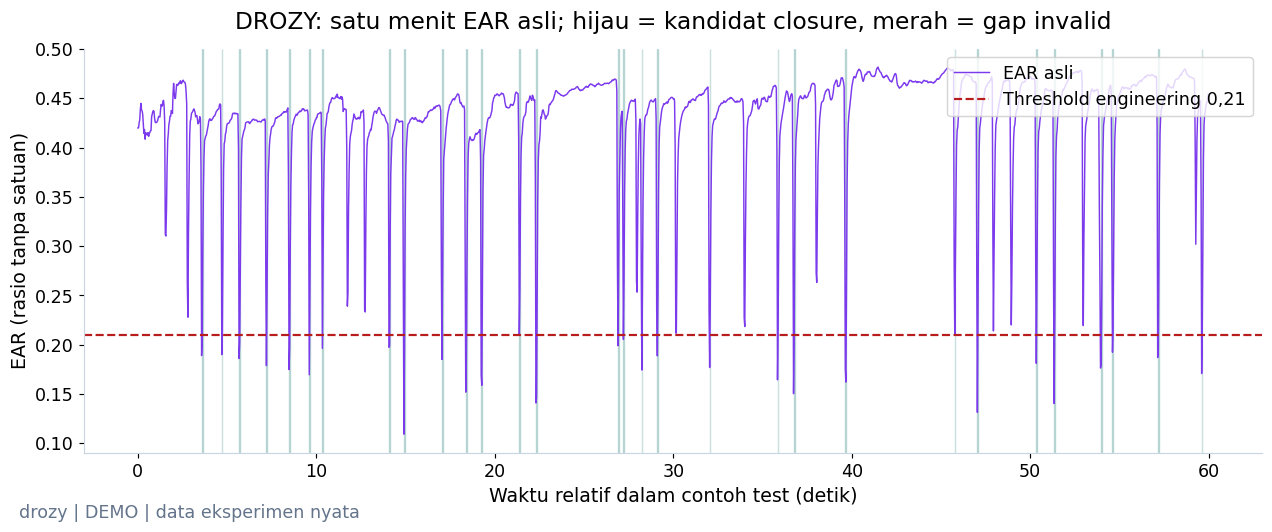

**Yang terlihat:** Terdapat 91 kandidat blink selesai pada seluruh contoh test.

**Artinya:** Event menghitung rentang penutupan, bukan jumlah frame yang berada di bawah threshold.

**Perlu diingat:** Grafik hanya menit pertama; event kandidat belum diverifikasi manual sebagai kedipan fisiologis.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [17]:
relative_ms = timestamps_ms-timestamps_ms[0]
first_minute = relative_ms <= 60000
fig, ax = plt.subplots(figsize=(12,4.8),layout='constrained')
ax.plot(relative_ms[first_minute]/1000,ear_values[first_minute],color=COLORS['visual'],lw=1,label='EAR asli')
ax.axhline(config['visual']['ear_threshold'],color=COLORS['error'],ls='--',label='Threshold engineering 0,21')
for event in eye_events:
    start = (event.start_ms-timestamps_ms[0])/1000
    end = (event.end_ms-timestamps_ms[0])/1000
    if 0 <= start < 60:
        ax.axvspan(start,min(end,60),color=COLORS['fusion'],alpha=0.22)
for gap_index in np.flatnonzero(np.diff(timestamps_ms)>config['visual']['max_gap_ms']):
    if relative_ms[gap_index]<60000:
        ax.axvspan(relative_ms[gap_index]/1000,min(relative_ms[gap_index+1]/1000,60),color=COLORS['error'],alpha=0.25)
ax.set(xlabel='Waktu relatif dalam contoh test (detik)',ylabel='EAR (rasio tanpa satuan)',
       title='DROZY: satu menit EAR asli; hijau = kandidat closure, merah = gap invalid')
ax.legend(loc='upper right')
drozy_book.show(fig,'ear_dan_events',
                f'Terdapat {sum(e.completed and 50<=e.end_ms-e.start_ms<=500 for e in eye_events)} kandidat blink selesai pada seluruh contoh test.',
                'Event menghitung rentang penutupan, bukan jumlah frame yang berada di bawah threshold.',
                'Grafik hanya menit pertama; event kandidat belum diverifikasi manual sebagai kedipan fisiologis.')

### 2.2 Dari frame menjadi window: kualitas dan definisi penutupan

Gap timestamp >150 ms tidak dianggap pengamatan baru dan tidak diinterpolasi. Window 60 detik memerlukan coverage ≥80%. **Blink** adalah event yang selesai, dengan mata terbuka yang teramati di kedua batas dan durasi engineering 50–500 ms.

**PERCLOS operasional** merangkum proporsi durasi closure yang sudah teramati minimal 500 ms di akhir window. Ukuran ini **belum tervalidasi sebagai definisi baku kelopak 80% tertutup**. Threshold EAR 0,21 belum dikalibrasi. Sensitivitas 0,18/0,21/0,24 ditunjukkan tanpa memilih threshold berdasarkan skor KSS.

In [18]:
if RUN_MODE == 'FULL':
    drozy_window_parts, sensitivity_rows, frame_qc = [], [], []
    for test in drozy_manifest.itertuples():
        points_path = drozy_root / f'annotations-auto/{test.session_id}-s2.txt'
        timestamp_path = drozy_root / f'timestamps/{test.session_id}.txt'
        window_path = drozy_run.file(f'features/windows/{test.session_id}.parquet')
        test_windows = process_test(points_path,timestamp_path,test.subject_id,test.session_id,config['visual'],window_path)
        test_windows['target_value'] = test.target_value
        test_windows['label_source'] = 'original_KSS.txt_subject_test; not_independent_window_labels'
        drozy_window_parts.append(test_windows)
        frames = pd.read_parquet(window_path.with_suffix('.frames.parquet'))
        frame_qc.append({'session_id':test.session_id,'frames':len(frames),
                         'gaps_gt150ms':int((frames.timestamp_ms.diff()>config['visual']['max_gap_ms']).sum())})
        for threshold in config['visual']['sensitivity_thresholds']:
            threshold_windows = window_features(frames.timestamp_ms,frames.ear_mean,{**config['visual'],'ear_threshold':threshold})
            sensitivity_rows.append({'session_id':test.session_id,'threshold':threshold,
                                      'perclos':threshold_windows.perclos.mean(),
                                      'blink_rate_per_min':threshold_windows.blink_rate_per_min.mean()})
    drozy_windows = pd.concat(drozy_window_parts,ignore_index=True)
    sensitivity = pd.DataFrame(sensitivity_rows)
    drozy_windows.to_parquet(drozy_run.file('features/windows.parquet'),index=False)
    sensitivity.to_csv(drozy_run.file('features/threshold_sensitivity.csv'),index=False)
    drozy_run.write('features/frame_qc.json',frame_qc)
else:
    drozy_windows = pd.read_parquet(drozy_run.path / 'features/windows.parquet')
    sensitivity = pd.read_csv(drozy_run.path / 'features/threshold_sensitivity.csv')
    frame_qc = json.loads((drozy_run.path / 'features/frame_qc.json').read_text())
cached_example = drozy_windows[drozy_windows.session_id.eq(example_test.session_id)]
np.testing.assert_allclose(live_windows.perclos,cached_example.perclos,equal_nan=True)
display(drozy_windows[['window_start_ms','window_end_ms','ear_mean','blink_rate_per_min','perclos','valid_coverage']].head())

,window_start_ms,window_end_ms,ear_mean,blink_rate_per_min,perclos,valid_coverage
0,23.0,60023.0,0.429510,12.000000,0.0,1.000000
1,60023.0,120023.0,0.436223,15.153811,0.0,0.989850
2,120023.0,180023.0,0.453793,4.021246,0.0,0.994717
3,180023.0,240023.0,0.456470,6.112677,0.0,0.981567
4,240023.0,300023.0,0.443432,9.049774,0.0,0.994500


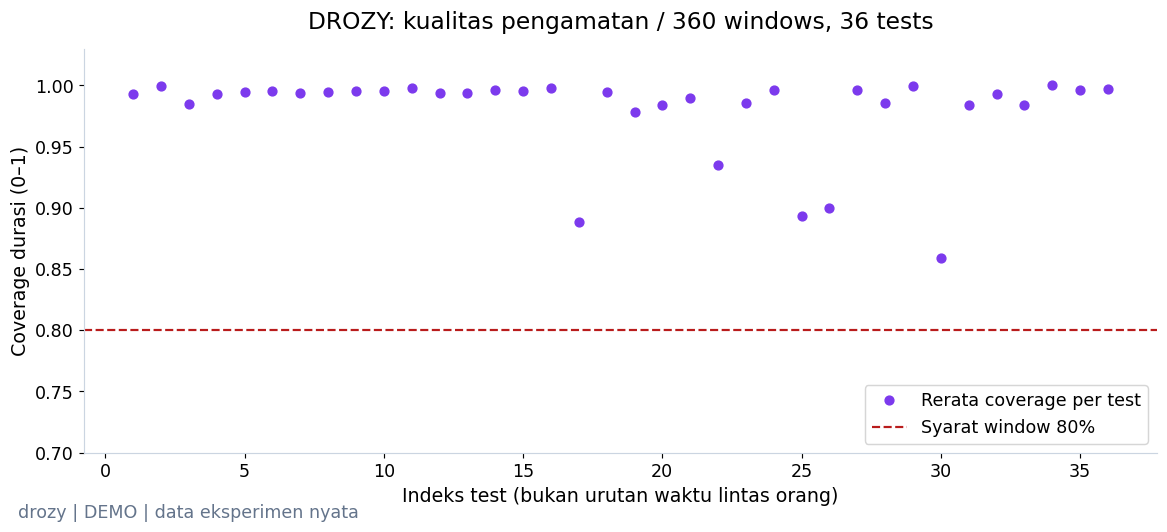

**Yang terlihat:** 348/360 windows tersedia; total gap >150 ms: 1041.

**Artinya:** Coverage menjaga agar waktu yang tidak teramati tidak ikut dihitung sebagai mata terbuka/tertutup.

**Perlu diingat:** Coverage baik tidak menjamin landmark akurat; pose dan kacamata masih perlu QC.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [19]:
coverage_summary = drozy_windows.groupby('session_id').valid_coverage.mean().sort_index()
fig, ax = plt.subplots(layout='constrained')
ax.plot(range(1,len(coverage_summary)+1),coverage_summary,'o',color=COLORS['visual'],label='Rerata coverage per test')
ax.axhline(config['visual']['min_coverage'],ls='--',color=COLORS['error'],label='Syarat window 80%')
ax.set(xlabel='Indeks test (bukan urutan waktu lintas orang)',ylabel='Coverage durasi (0–1)',ylim=(0.7,1.03),
       title=f'DROZY: kualitas pengamatan / {len(drozy_windows)} windows, {len(coverage_summary)} tests')
ax.legend(loc='lower right')
drozy_book.show(fig,'coverage_drozy',
                f'{int(drozy_windows.video_available.sum())}/{len(drozy_windows)} windows tersedia; total gap >150 ms: {sum(r["gaps_gt150ms"] for r in frame_qc)}.',
                'Coverage menjaga agar waktu yang tidak teramati tidak ikut dihitung sebagai mata terbuka/tertutup.',
                'Coverage baik tidak menjamin landmark akurat; pose dan kacamata masih perlu QC.')

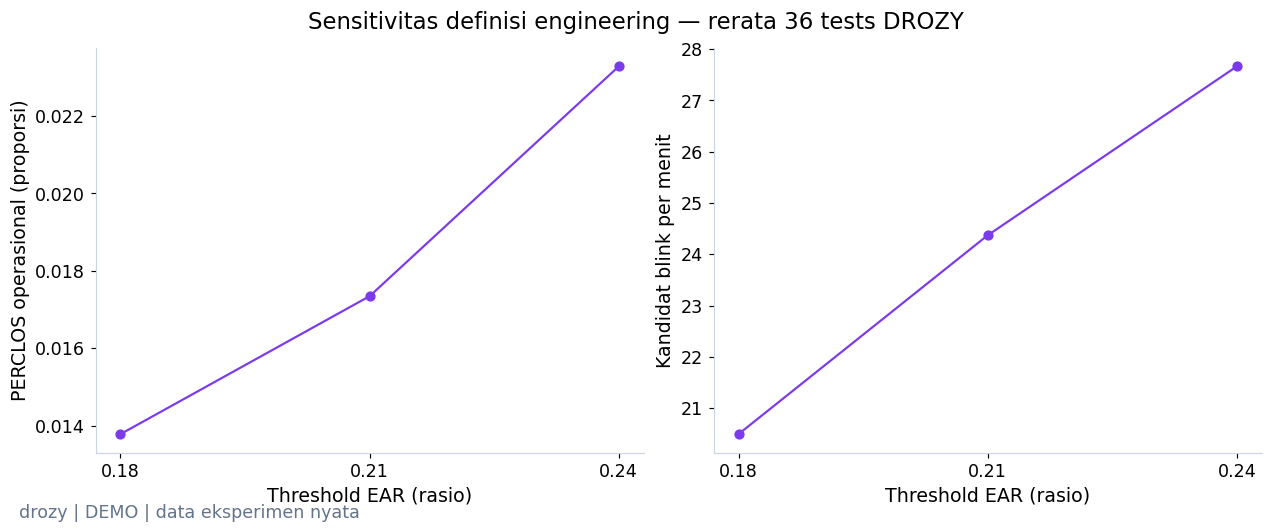

**Yang terlihat:** Mean PERCLOS berubah 0.0138–0.0233 pada threshold yang diperiksa.

**Artinya:** Fitur bergantung pada definisi closure; threshold bukan konstanta universal.

**Perlu diingat:** Model tetap memakai 0,21; tidak ada pemilihan threshold menggunakan hasil holdout KSS.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [20]:
threshold_means = sensitivity.groupby('threshold')[['perclos','blink_rate_per_min']].mean()
fig, axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
for ax,column,label in zip(axes,['perclos','blink_rate_per_min'],['PERCLOS operasional (proporsi)','Kandidat blink per menit']):
    ax.plot(threshold_means.index,threshold_means[column],'o-',color=COLORS['visual'])
    ax.set(xlabel='Threshold EAR (rasio)',ylabel=label,xticks=threshold_means.index)
fig.suptitle(f'Sensitivitas definisi engineering — rerata {drozy_manifest.shape[0]} tests DROZY')
drozy_book.show(fig,'sensitivitas_threshold',
                f"Mean PERCLOS berubah {threshold_means.perclos.min():.4f}–{threshold_means.perclos.max():.4f} pada threshold yang diperiksa.",
                'Fitur bergantung pada definisi closure; threshold bukan konstanta universal.',
                'Model tetap memakai 0,21; tidak ada pemilihan threshold menggunakan hasil holdout KSS.')

### 2.3 Satu baris per test dan sumber label

Window yang tersedia dirangkum menjadi rerata dan simpangan baku lima fitur, total sepuluh fitur per test. KSS dibaca dari `KSS.txt` pada pasangan subjek/test asli; nilai dummy 0 tidak menjadi target. **360 windows → 36 baris per test**, dengan pengukuran berulang dalam 14 subjek; 36 baris ini pun bukan 36 orang independen.

,Windows,Original tests,Subjek,Fitur per test
0,360,36,14,10


,usable_windows,ear_mean_mean,blink_rate_per_min_mean,perclos_mean,KSS asli per test
0,10,0.439414,9.158735,0.000000,3.0
1,10,0.419268,20.205730,0.001003,6.0
2,10,0.418600,19.518430,0.000000,7.0
3,10,0.368781,32.539184,0.000000,3.0
4,10,0.414012,38.741811,0.000000,7.0


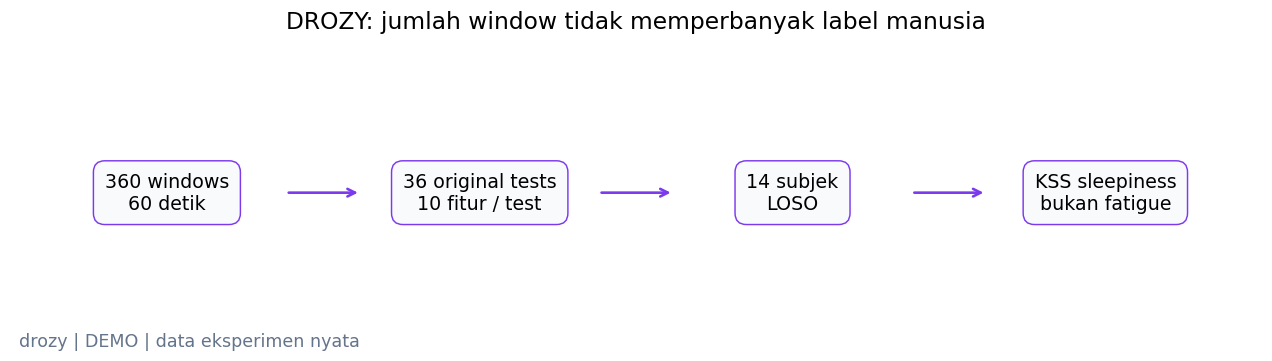

**Yang terlihat:** Satu KSS asli dipasangkan dengan satu agregat test.

**Artinya:** Evaluasi mempertahankan resolusi label dan menahan subjek yang sama di satu fold uji.

**Perlu diingat:** Whole-test features memakai seluruh rekaman offline; bukan prediksi awal atau real-time.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [21]:
kss_data, kss_columns = kss_test_table(drozy_windows)
assert len(kss_data)==len(drozy_manifest) and kss_data.target_value.between(1,9).all()
display(pd.DataFrame([{'Windows':len(drozy_windows),'Original tests':len(kss_data),
                       'Subjek':kss_data.subject_id.nunique(),'Fitur per test':len(kss_columns)}]))
display(kss_data[['usable_windows','ear_mean_mean','blink_rate_per_min_mean','perclos_mean','target_value']].head()
        .rename(columns={'target_value':'KSS asli per test'}))
if RUN_MODE=='FULL':
    drozy_run.features(kss_data,kss_columns,'ear68-duration-v1; test-aggregate-v1')
fig = flow([f'{len(drozy_windows)} windows\n60 detik',f'{len(kss_data)} original tests\n10 fitur / test',
            f'{kss_data.subject_id.nunique()} subjek\nLOSO', 'KSS sleepiness\nbukan fatigue'],
           COLORS['visual'],'DROZY: jumlah window tidak memperbanyak label manusia')
drozy_book.show(fig,'window_ke_test','Satu KSS asli dipasangkan dengan satu agregat test.',
                'Evaluasi mempertahankan resolusi label dan menahan subjek yang sama di satu fold uji.',
                'Whole-test features memakai seluruh rekaman offline; bukan prediksi awal atau real-time.')

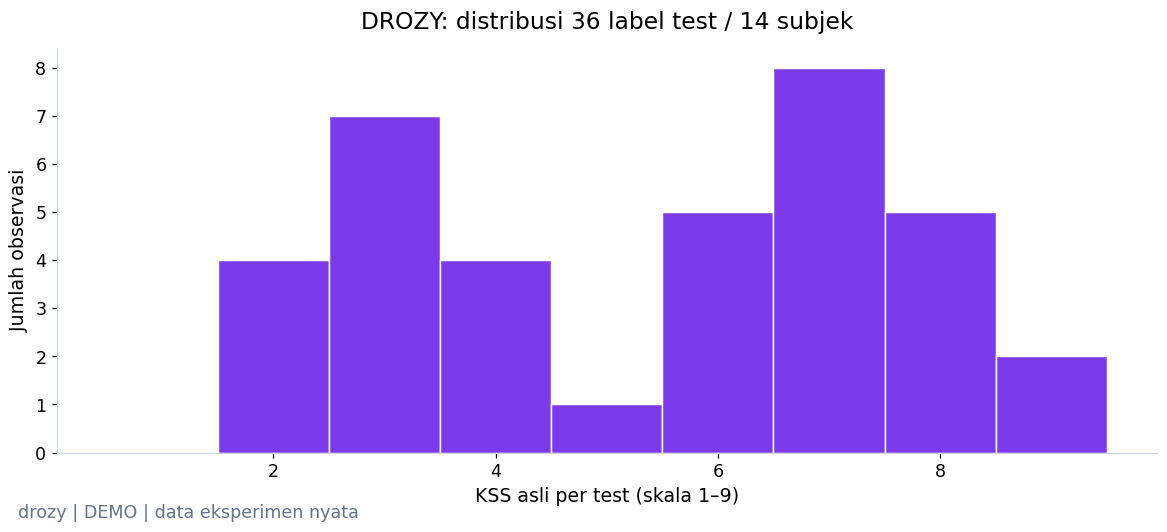

**Yang terlihat:** Skor KSS yang tersedia berkisar 2–9.

**Artinya:** Target adalah angka rasa kantuk subjektif, sehingga masalah ini diperlakukan sebagai regresi.

**Perlu diingat:** Histogram berunit test, tidak dihitung ulang per window; nilai dummy nol tidak dimasukkan.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [22]:
fig = histogram(kss_data.target_value.to_numpy(float),'KSS asli per test (skala 1–9)',
                f'DROZY: distribusi {len(kss_data)} label test / {kss_data.subject_id.nunique()} subjek',COLORS['visual'],bins=np.arange(0.5,10,1))
drozy_book.show(fig,'distribusi_kss',
                f'Skor KSS yang tersedia berkisar {kss_data.target_value.min():.0f}–{kss_data.target_value.max():.0f}.',
                'Target adalah angka rasa kantuk subjektif, sehingga masalah ini diperlakukan sebagai regresi.',
                'Histogram berunit test, tidak dihitung ulang per window; nilai dummy nol tidak dimasukkan.')

### 2.4 Training LOSO yang dapat diperiksa

**LOSO** (*Leave-One-Subject-Out*) melatih model pada semua orang kecuali satu, lalu menguji seluruh tests orang yang ditahan. Ini diulang untuk 14 orang. Pada setiap fold, median dan skala hanya dipelajari dari training.

**Dummy mean** menebak KSS rerata training. **Ridge** adalah regresi linear dengan pembatasan besar koefisien (`alpha=1`) untuk mengurangi kecocokan berlebihan pada sampel kecil. FULL menjalankan seluruh fold; DEMO menguji ulang inference satu fold dari checkpoint tersimpan, tanpa mengaku melakukan training ulang.

,Fold,Subjek train,Subjek test,Tests train,Tests uji
0,1,13,1,33,3
1,2,13,1,34,2
2,3,13,1,33,3
3,4,13,1,35,1
4,5,13,1,34,2


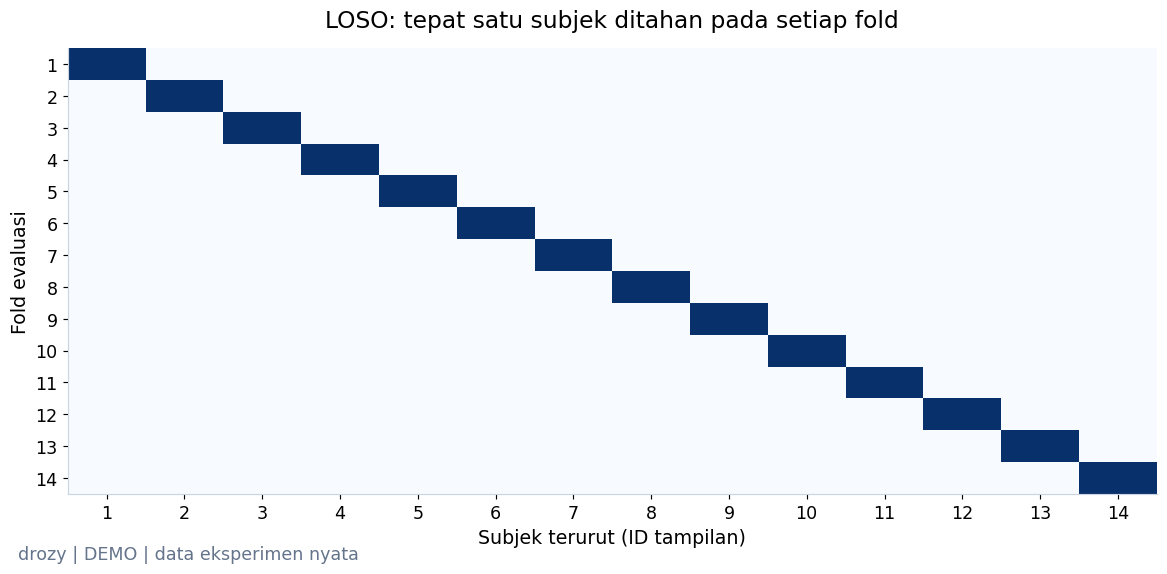

**Yang terlihat:** Sel biru menunjukkan subjek test; subjek lainnya menjadi training.

**Artinya:** Tidak ada data orang yang sedang diuji untuk fit model atau preprocessing fold tersebut.

**Perlu diingat:** LOSO pada korpus kecil belum menggantikan validasi pada operator ATC.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [23]:
kss_folds = list(LeaveOneGroupOut().split(kss_data,groups=kss_data.subject_id))
fold_display = []
for fold_index,(training_indices,test_indices) in enumerate(kss_folds):
    training_subjects = set(kss_data.iloc[training_indices].subject_id)
    heldout_subjects = set(kss_data.iloc[test_indices].subject_id)
    assert not training_subjects & heldout_subjects
    fold_display.append({'Fold':fold_index+1,'Subjek train':len(training_subjects),'Subjek test':len(heldout_subjects),
                         'Tests train':len(training_indices),'Tests uji':len(test_indices)})
display(pd.DataFrame(fold_display).head())
membership = np.zeros((len(kss_folds),kss_data.subject_id.nunique()))
subject_order = sorted(kss_data.subject_id.unique())
for i,(_,heldout_indices) in enumerate(kss_folds):
    membership[i,subject_order.index(kss_data.iloc[heldout_indices].subject_id.iloc[0])] = 1
fig, ax = plt.subplots(figsize=(11,5.2),layout='constrained')
ax.imshow(membership,aspect='auto',cmap='Blues',vmin=0,vmax=1)
ax.set(xlabel='Subjek terurut (ID tampilan)',ylabel='Fold evaluasi',title='LOSO: tepat satu subjek ditahan pada setiap fold',
       xticks=range(len(subject_order)),xticklabels=range(1,len(subject_order)+1),
       yticks=range(len(kss_folds)),yticklabels=range(1,len(kss_folds)+1))
drozy_book.show(fig,'diagram_loso','Sel biru menunjukkan subjek test; subjek lainnya menjadi training.',
                'Tidak ada data orang yang sedang diuji untuk fit model atau preprocessing fold tersebut.',
                'LOSO pada korpus kecil belum menggantikan validasi pada operator ATC.')

In [24]:
if RUN_MODE=='FULL':
    kss_prediction_parts, fold_manifests, fold_rows = [], [], []
    for fold_index,(training_indices,test_indices) in enumerate(kss_folds):
        training,holdout = kss_data.iloc[training_indices],kss_data.iloc[test_indices]
        fold_manifests.append({'fold':fold_index,'train_subjects':sorted(training.subject_id.unique()),
                               'test_subjects':sorted(holdout.subject_id.unique())})
        for partition,subset in [('train',training),('test',holdout)]:
            fold_rows.append(subset[['sample_id','subject_id','session_id','target_value']].assign(fold=fold_index,split=partition))
        for model_name,estimator in [('dummy_mean',DummyRegressor()),('ridge_alpha1',Ridge(alpha=1.0))]:
            model = make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),estimator)
            model.fit(training[kss_columns],training.target_value)
            predicted = save_model(drozy_run,f'{model_name}_fold{fold_index:02d}',model,kss_columns,holdout)
            kss_prediction_parts.append(prediction_table(holdout,predicted,model_name,fold=fold_index))
    kss_predictions = pd.concat(kss_prediction_parts,ignore_index=True)
    kss_predictions.to_csv(drozy_run.file('predictions/holdout_predictions.csv'),index=False)
    pd.concat(fold_rows).to_csv(drozy_run.file('split_manifest.csv'),index=False)
    drozy_run.write('folds.json',fold_manifests)
    kss_scores = {name:regression_metrics(group) for name,group in kss_predictions.groupby('model')}
    kss_metrics = metrics_base(drozy_run,kss_scores,{'train':{'per_fold':[len(t) for t,_ in kss_folds]},
                              'test':len(kss_data)}, {'KSS':'original per-test 1–9'},'dummy_mean')
else:
    kss_predictions = pd.read_csv(drozy_run.path / 'predictions/holdout_predictions.csv',dtype={'subject_id':str})
    first_holdout = kss_data.iloc[kss_folds[0][1]]
    for model_name in ['dummy_mean','ridge_alpha1']:
        verify_cached_predictions(drozy_run,first_holdout,kss_predictions[kss_predictions.fold.eq(0)],
                                   model_name,f'{model_name}_fold00')
display(pd.DataFrame(kss_metrics['models']).T[['mae','rmse','subject_macro_mae']])

,mae,rmse,subject_macro_mae
dummy_mean,2.051866,2.270424,2.108202
ridge_alpha1,1.45444,1.817016,1.44051


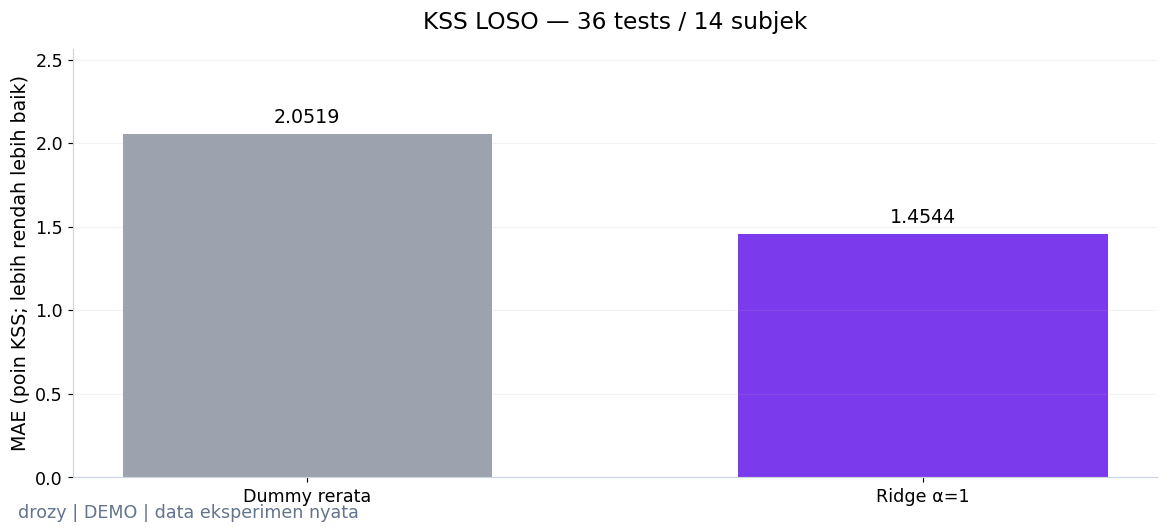

**Yang terlihat:** Ridge MAE 1.4544; Dummy 2.0519 poin KSS.

**Artinya:** MAE adalah rata-rata besar selisih prediksi terhadap label; nilainya dalam satuan poin KSS.

**Perlu diingat:** Angka ini tidak dapat dibandingkan langsung dengan Macro F1 klasifikasi MRL atau RAVDESS.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [25]:
fig = model_bars(kss_metrics['models'],'mae',f'KSS LOSO — {len(kss_data)} tests / {kss_data.subject_id.nunique()} subjek',
                 'MAE (poin KSS; lebih rendah lebih baik)',COLORS['visual'])
drozy_book.show(fig,'baseline_mae_kss',
                f"Ridge MAE {kss_metrics['models']['ridge_alpha1']['mae']:.4f}; Dummy {kss_metrics['models']['dummy_mean']['mae']:.4f} poin KSS.",
                'MAE adalah rata-rata besar selisih prediksi terhadap label; nilainya dalam satuan poin KSS.',
                'Angka ini tidak dapat dibandingkan langsung dengan Macro F1 klasifikasi MRL atau RAVDESS.')

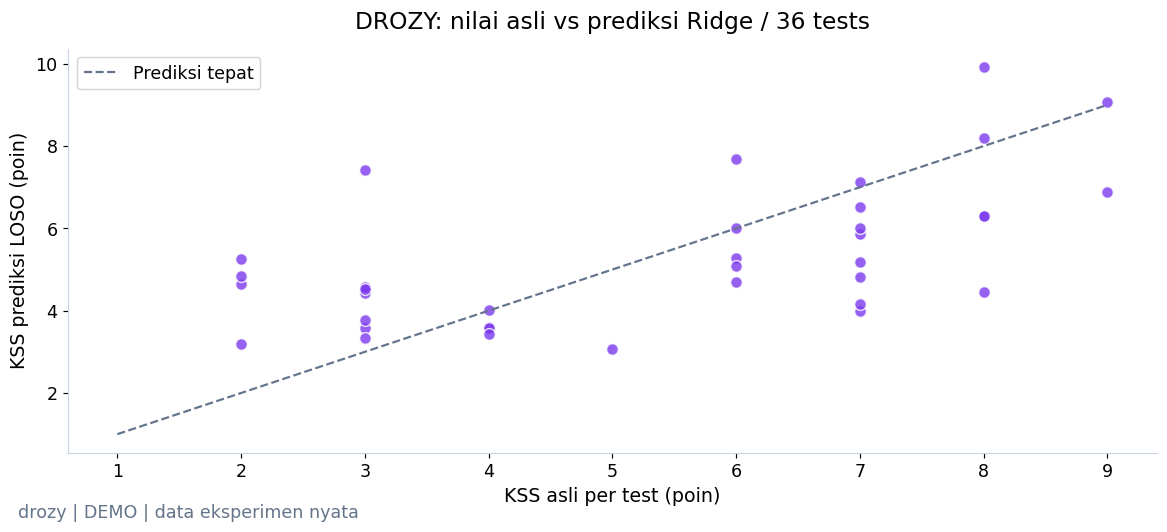

**Yang terlihat:** RMSE Ridge 1.8170 poin; titik di luar garis adalah error nyata.

**Artinya:** Jarak vertikal menunjukkan seberapa jauh prediksi tiap test dari penilaian subjek.

**Perlu diingat:** Prediksi regresi tidak dipotong ke 1–9; angka ekstrem tetap terlihat sebagai kegagalan.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [26]:
ridge_holdout = kss_predictions[kss_predictions.model.eq('ridge_alpha1')].copy()
ridge_holdout['residual'] = ridge_holdout.prediction-ridge_holdout.truth
fig,ax = plt.subplots(layout='constrained')
ax.scatter(ridge_holdout.truth,ridge_holdout.prediction,s=65,alpha=0.8,color=COLORS['visual'],edgecolor='white')
ax.plot([1,9],[1,9],'--',color=COLORS['secondary'],label='Prediksi tepat')
ax.set(xlabel='KSS asli per test (poin)',ylabel='KSS prediksi LOSO (poin)',
       title=f'DROZY: nilai asli vs prediksi Ridge / {len(ridge_holdout)} tests')
ax.legend()
drozy_book.show(fig,'aktual_vs_prediksi_kss',
                f"RMSE Ridge {kss_metrics['models']['ridge_alpha1']['rmse']:.4f} poin; titik di luar garis adalah error nyata.",
                'Jarak vertikal menunjukkan seberapa jauh prediksi tiap test dari penilaian subjek.',
                'Prediksi regresi tidak dipotong ke 1–9; angka ekstrem tetap terlihat sebagai kegagalan.')

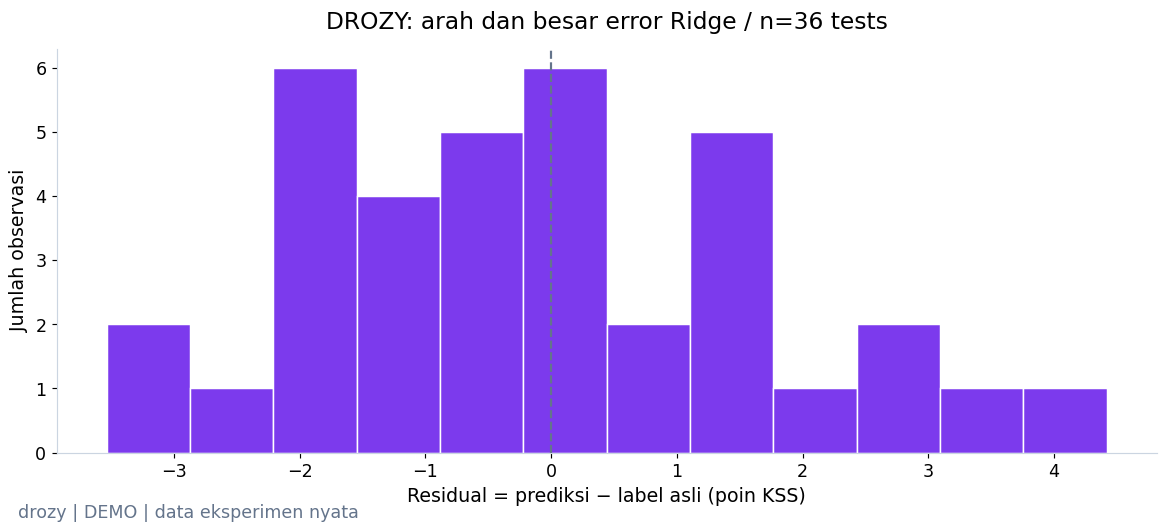

**Yang terlihat:** Residual rerata -0.085 poin; residual negatif berarti kantuk diperkirakan terlalu rendah.

**Artinya:** Distribusi error membantu melihat bias arah yang tidak tampak pada MAE saja.

**Perlu diingat:** Ukuran sampel kecil dan tests berulang membuat histogram ini deskriptif, bukan bukti kalibrasi.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

In [27]:
fig = histogram(ridge_holdout.residual.to_numpy(float),'Residual = prediksi − label asli (poin KSS)',
                f'DROZY: arah dan besar error Ridge / n={len(ridge_holdout)} tests',COLORS['visual'],bins=12)
fig.axes[0].axvline(0,color=COLORS['secondary'],ls='--')
drozy_book.show(fig,'residual_kss',
                f'Residual rerata {ridge_holdout.residual.mean():.3f} poin; residual negatif berarti kantuk diperkirakan terlalu rendah.',
                'Distribusi error membantu melihat bias arah yang tidak tampak pada MAE saja.',
                'Ukuran sampel kecil dan tests berulang membuat histogram ini deskriptif, bukan bukti kalibrasi.')

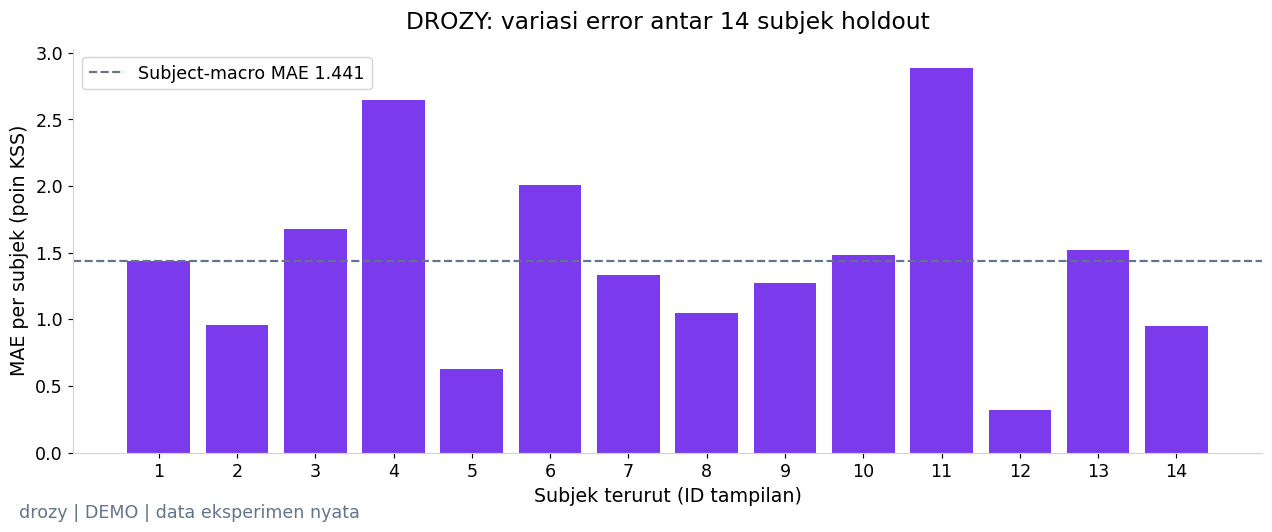

**Yang terlihat:** MAE per subjek berkisar 0.322–2.887 poin.

**Artinya:** Subject-macro MAE memberi bobot sama pada setiap orang, meski jumlah tests berbeda.

**Perlu diingat:** Variasi ini belum merupakan interval keyakinan generalisasi ke populasi ATC.

*Sumber: `20261022T082144167968Z_seed42_60423d` · CACHED + contoh diproses langsung.*

,KSS asli,Prediksi,Residual (poin)
56,3.0,7.418879,4.418879
51,8.0,4.464907,-3.535093
55,2.0,5.254549,3.254549
5,7.0,3.986133,-3.013867
65,2.0,4.850213,2.850213


In [28]:
subject_mae = ridge_holdout.assign(error=ridge_holdout.residual.abs()).groupby('subject_id').error.mean().sort_index()
fig,ax = plt.subplots(figsize=(12,4.8),layout='constrained')
ax.bar(range(1,len(subject_mae)+1),subject_mae,color=COLORS['visual'])
ax.axhline(subject_mae.mean(),color=COLORS['secondary'],ls='--',label=f'Subject-macro MAE {subject_mae.mean():.3f}')
ax.set(xlabel='Subjek terurut (ID tampilan)',ylabel='MAE per subjek (poin KSS)',
       title='DROZY: variasi error antar 14 subjek holdout',xticks=range(1,len(subject_mae)+1))
ax.legend()
drozy_book.show(fig,'mae_per_subjek_kss',
                f'MAE per subjek berkisar {subject_mae.min():.3f}–{subject_mae.max():.3f} poin.',
                'Subject-macro MAE memberi bobot sama pada setiap orang, meski jumlah tests berbeda.',
                'Variasi ini belum merupakan interval keyakinan generalisasi ke populasi ATC.')
display(ridge_holdout.assign(error=ridge_holdout.residual.abs()).sort_values('error',ascending=False)
        [['truth','prediction','residual']].head(5).rename(columns={'truth':'KSS asli','prediction':'Prediksi','residual':'Residual (poin)'}))

## 3. Interpretasi dan hubungan ke riset ATC

MRL menunjukkan kemampuan mengenali keadaan mata pada gambar. DROZY menunjukkan perhitungan fitur temporal serta hubungan prediktif awal terhadap sleepiness KSS. Tidak ada model yang mengubah dua label tersebut menjadi fatigue ATC.

Landmark otomatis dan threshold belum tervalidasi luas; whole-test aggregation belum cocok untuk peringatan dini. Validasi berikutnya membutuhkan anotasi event/closure, protokol waktu label, video berkualitas, dan data ATC yang sah. Kita tidak membuat pasangan MRL–DROZY atau ATCOSIM–DROZY untuk memperoleh skor gabungan.

## 4. Provenance dan reproduksi

MRL dan DROZY memiliki run, schema, model, split/fold, prediksi dan grafik masing-masing. Model disimpan dengan urutan fitur dan reload diverifikasi. KSS mempertahankan 36 original test rows, bukan 360 observasi berlabel independen.

In [29]:
drozy_book.finish()
if RUN_MODE=='FULL':
    drozy_run.complete(kss_metrics,{'evaluation_rows':len(kss_data),'subjects':int(kss_data.subject_id.nunique()),
                                   'windows':len(drozy_windows),'usable_windows':int(drozy_windows.video_available.sum()),
                                   'subject_overlap':0,'whole_test_offline':True},warning_records)
display(pd.DataFrame([{'Eksperimen':'MRL eye state','Run ID':mrl_run.manifest['run_id'],'Mode':RUN_MODE,
                       'Artifact':str(mrl_run.path.relative_to(ROOT))},
                      {'Eksperimen':'DROZY KSS','Run ID':drozy_run.manifest['run_id'],'Mode':RUN_MODE,
                       'Artifact':str(drozy_run.path.relative_to(ROOT))}]))
warning_context.__exit__(None,None,None)

,Eksperimen,Run ID,Mode,Artifact
0,MRL eye state,20261022T082130453246Z_seed42_6453bd,DEMO,runs/mrl_eye_state/20261022T082130453246Z_seed...
1,DROZY KSS,20261022T082144167968Z_seed42_60423d,DEMO,runs/drozy_kss/20261022T082144167968Z_seed42_6...


**Kesimpulan:** gambar dan urutan mata dapat diproses, baseline dapat dilatih, dan kegagalan dapat ditelusuri. Skor tetap terpisah menurut target. Lanjut ke [notebook fusion](03_multimodal_fusion.ipynb) untuk menguji audio-video yang benar-benar berpasangan. [Petunjuk FULL/DEMO](README.md).